In [25]:
import torch 
%matplotlib widget

In [26]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [27]:
from torch import nn
class PolicyNetwork(nn.Module): 
    def __init__(self): 
        super().__init__() # Not sure what this is but it looks like it's standard to stick at the start of the class.
        self.flatten = nn.Flatten() # this flattens the data array which might not be a vector but rather a matrix.
        # Neural network architecture:
        self.linear_relu_softmax = nn.Sequential(
            nn.Linear(4*4 , 10),
            nn.ReLU(), 
            nn.Linear(10 , 6), 
            nn.ReLU(), 
            nn.Linear(6 , 4), 
            nn.LogSoftmax(dim = 1)
        )

    # Define a forward pass through the network
    def forward(self , x): 
        # Invoke flatten to convert data array into a vector:
        x = self.flatten(x)
        # Run the input vector through the neural network to compute the outputs (called 'logits')
        logits = self.linear_relu_softmax(x)
        return logits

class PlotNetwork(nn.Module):
    def __init__(self): 
        super().__init__() 
        self.flatten = nn.Flatten() 
        # Neural network architecture:
        self.neural_pass_plot = nn.Sequential(
            nn.Linear(4*4 , 10),
        
            nn.Linear(10 , 6), 
        
            nn.Linear(6 , 4), 
    
        )

    def forward(self , x):
        x = self.flatten(x) 
        logits = self.neural_pass_plot(x)
        return logits

In [28]:
policy_model = PolicyNetwork().to(device)
print(policy_model)
plotting_model = PlotNetwork()

PolicyNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_softmax): Sequential(
    (0): Linear(in_features=16, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=6, bias=True)
    (3): ReLU()
    (4): Linear(in_features=6, out_features=4, bias=True)
    (5): LogSoftmax(dim=1)
  )
)


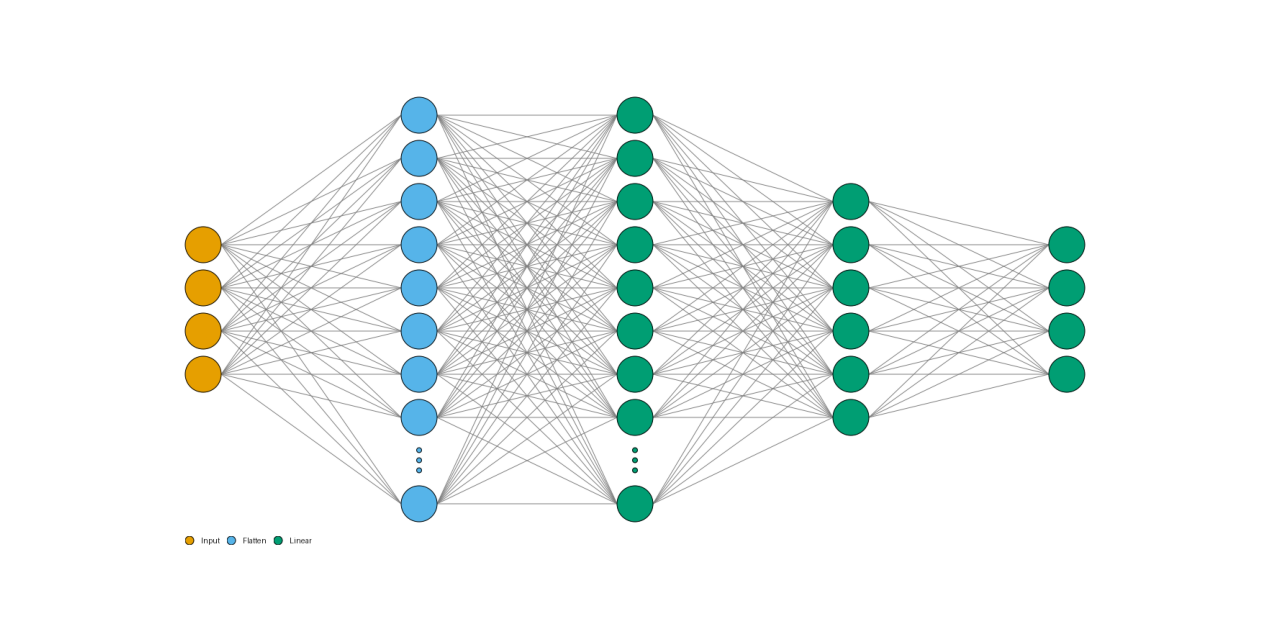

In [29]:
# Printing using a nice python package called visual torch: 
import visualtorch

img = visualtorch.render(
    PlotNetwork(),
    (1,4 , 4),
    style="graph",
    legend = True
)

dpi = 600  # rendered at 2x this in the final doc build (savefig.dpi=300 in conf.py)
import matplotlib.pyplot as plt
plt.figure(figsize=(img.width/dpi, img.height/dpi), dpi=dpi)
plt.imshow(img)
plt.axis("off")
plt.tight_layout()
plt.show()

In [30]:
# Loading a 2048 game state: 
test_game_state = torch.tensor([[[ 0 , 0 , 0 , 0],
 [ 0 , 2 , 0 , 0],
 [16 , 0 , 0 , 0],
 [ 2 , 2 , 0 , 0]]], dtype = torch.float32, device=device)

test_output = policy_model(test_game_state)

Using the test game state, let us write a script that will generate an episode of experience using the policy model as it currently stands

In [31]:
# Probabilities associated with up, down, left and right respectively:
probs = torch.exp(test_output[0])
print(probs)
# Random number generator: 
import numpy as np
action_indices = [0 , 1 , 2 , 3]
test_action = np.random.choice(action_indices , p = probs.detach().numpy())

# Action index to string dictionary: 
action_dict = {0 : 'up' , 1 : 'down' , 2 : 'left' , 3 : 'right', 4 : 'quit'}

# Printing test action: 
action_dict[test_action]

tensor([0.2710, 0.1502, 0.2447, 0.3341], grad_fn=<ExpBackward0>)


'right'

In [32]:
from game_agent_friendly import Agent, generate
# Create an agent following this policy:
agent = Agent(policy_model , device)
# Initial state for the game:
state_0 = np.array([[0 , 0 , 0 , 0] , [0 , 2 , 0 , 0] , [0 , 0 , 2 , 0 ] , [0 , 0 ,0 , 0]])
# Generate an episode of experience using the 'generate' function:
episode = generate(state_0, agent)

Gameover?:  False
down
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 0]
 [0 2 2 0]]
Gameover?:  False
right
[[0 0 2 0]
 [0 0 0 2]
 [0 0 0 0]
 [0 0 0 4]]
Gameover?:  False
down
[[0 0 0 2]
 [0 0 0 0]
 [0 0 0 2]
 [0 0 2 4]]
Gameover?:  False
up
[[0 0 2 4]
 [0 0 0 4]
 [0 0 0 0]
 [2 0 0 0]]
Gameover?:  False
down
[[0 0 2 0]
 [0 0 0 0]
 [0 0 0 0]
 [2 0 2 8]]
Gameover?:  False
left
[[2 0 0 0]
 [0 2 0 0]
 [0 0 0 0]
 [4 8 0 0]]
Gameover?:  False
right
[[0 0 0 2]
 [0 0 0 2]
 [0 0 0 0]
 [2 0 4 8]]
Gameover?:  False
up
[[2 0 4 4]
 [0 0 0 8]
 [2 0 0 0]
 [0 0 0 0]]
Gameover?:  False
right
[[0 2 2 8]
 [0 0 0 8]
 [0 0 0 2]
 [0 0 0 0]]
Gameover?:  False
left
[[4 8 0 0]
 [8 0 0 0]
 [2 0 0 2]
 [0 0 0 0]]
Gameover?:  False
down
[[2 0 0 0]
 [4 0 0 0]
 [8 0 0 0]
 [2 8 0 2]]
Gameover?:  False
left
[[2 0 0 0]
 [4 0 0 0]
 [8 0 0 2]
 [2 8 2 0]]
Gameover?:  False
down
[[2 0 0 2]
 [4 0 0 0]
 [8 0 0 0]
 [2 8 2 2]]
Gameover?:  False
up
[[2 8 2 4]
 [4 0 0 0]
 [8 0 0 2]
 [2 0 0 0]]
Gameover?:  False
left
[[2 8 2 4]
 [4 0 0 0]
 [8 2 

In [33]:
states , actions, rewards = episode
print('Length of episode: ' , len(states))

Length of episode:  338


In [37]:
for i in states: 
    print(i)

[[0 0 0 0]
 [0 2 0 0]
 [0 0 2 0]
 [0 0 0 0]]
[[0 0 0 0]
 [0 0 0 2]
 [0 0 0 0]
 [0 2 2 0]]
[[0 0 2 0]
 [0 0 0 2]
 [0 0 0 0]
 [0 0 0 4]]
[[0 0 0 2]
 [0 0 0 0]
 [0 0 0 2]
 [0 0 2 4]]
[[0 0 2 4]
 [0 0 0 4]
 [0 0 0 0]
 [2 0 0 0]]
[[0 0 2 0]
 [0 0 0 0]
 [0 0 0 0]
 [2 0 2 8]]
[[2 0 0 0]
 [0 2 0 0]
 [0 0 0 0]
 [4 8 0 0]]
[[0 0 0 2]
 [0 0 0 2]
 [0 0 0 0]
 [2 0 4 8]]
[[2 0 4 4]
 [0 0 0 8]
 [2 0 0 0]
 [0 0 0 0]]
[[0 2 2 8]
 [0 0 0 8]
 [0 0 0 2]
 [0 0 0 0]]
[[4 8 0 0]
 [8 0 0 0]
 [2 0 0 2]
 [0 0 0 0]]
[[2 0 0 0]
 [4 0 0 0]
 [8 0 0 0]
 [2 8 0 2]]
[[2 0 0 0]
 [4 0 0 0]
 [8 0 0 2]
 [2 8 2 0]]
[[2 0 0 2]
 [4 0 0 0]
 [8 0 0 0]
 [2 8 2 2]]
[[2 8 2 4]
 [4 0 0 0]
 [8 0 0 2]
 [2 0 0 0]]
[[2 8 2 4]
 [4 0 0 0]
 [8 2 0 0]
 [2 0 0 4]]
[[2 8 2 4]
 [0 0 0 4]
 [2 0 8 2]
 [0 0 2 4]]
[[2 8 2 4]
 [0 0 0 4]
 [2 2 8 2]
 [0 0 2 4]]
[[0 0 0 0]
 [2 0 2 8]
 [0 8 8 2]
 [4 2 2 4]]
[[ 2  0  0  0]
 [ 0  0  4  8]
 [ 0  0 16  2]
 [ 0  4  4  4]]
[[ 0  0  0  2]
 [ 2  0  4  8]
 [ 0  0 16  2]
 [ 0  0  4  8]]
[[ 2  0  4  2]
 [ 0  0 

In [38]:
print(actions)

['down', 'right', 'down', 'up', 'down', 'left', 'right', 'up', 'right', 'left', 'down', 'left', 'down', 'up', 'left', 'right', 'right', 'down', 'right', 'right', 'up', 'left', 'left', 'right', 'right', 'right', 'right', 'up', 'left', 'left', 'left', 'right', 'right', 'up', 'right', 'right', 'left', 'right', 'right', 'right', 'up', 'right', 'up', 'right', 'up', 'up', 'down', 'right', 'right', 'left', 'left', 'right', 'down', 'right', 'up', 'left', 'up', 'right', 'down', 'up', 'left', 'down', 'right', 'up', 'up', 'right', 'down', 'up', 'right', 'left', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'right', 'left', 'right', 'right', 'right', 'right', 'left', 'right', 'right', 'right', 'left', 'left', 'right', 'right', 'right', 'right', 'up', 'left', 'right', 'right', 'right', 'up', 'right', 'left', 'right', 'right', 'right', 'up', 'right', 'left', 'down', 'right', 'right', '

Plotting instantaneous rewards and return at each time step:

Text(0.5, 1.0, 'Reward')

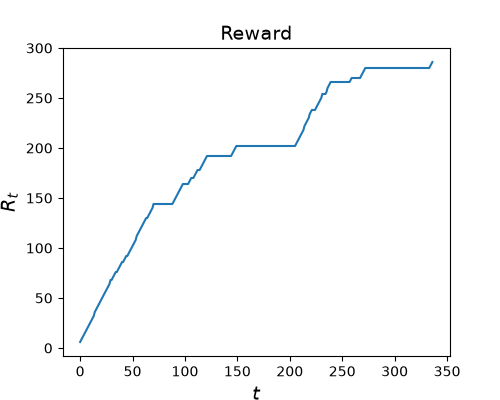

In [35]:
# Visualise rewards over time: 
fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards)
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_ylabel(r'$R_{t}$' , fontsize = 14)
ax.set_title('Reward' , fontsize = 14)

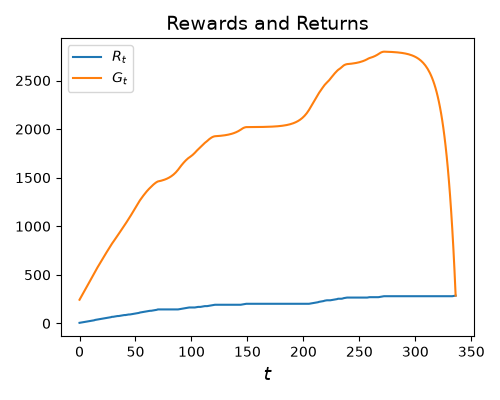

In [36]:
def G_t(t, rewards, episode_length, gamma): 
    '''
    Computes return in state at time t
    '''
    d = np.array([gamma**i for i in range(episode_length - t)])
    r = rewards[t:]
    return d@r 

G = [G_t(t , rewards , len(rewards), 0.9) for t in range(len(rewards))]

fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards, label = r'$R_{t}$')
ax.plot(G , label = r'$G_{t}$')
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_title('Rewards and Returns' , fontsize = 14)
ax.legend() 
plt.tight_layout()
    

Computing gradients of the policy network: